# LusoEnergia — Parte IV: Monitorizar o fluxo em tempo real

As funções do fluxo estão em `src/fluxo.py`, para serem reutilizadas no dashboard.

In [2]:
# Parte IV - configuração e dados tratados (gerados no notebook das Partes I e II)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from src.fluxo import Welford, JanelaDeslizante, EWMA
from src.utils import guardar_figura

AZUL, BORDO, TINTA, TINTA_2, GRELHA = "#2a78d6", "#7b1e3a", "#2b2b28", "#6b6a64", "#e4e3de"
CINZA_DADOS = "#c4c2ba"           # dados em bruto (leituras): sempre cinzento claro
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
MESES_PT = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]


def estilo(ax):
    """Eixos discretos: sem moldura, grelha leve (o mesmo estilo das Partes I e II)."""
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_color(GRELHA)
    ax.tick_params(colors=TINTA_2, labelsize=9, length=0)
    ax.grid(axis="y", color=GRELHA, lw=0.8)
    ax.set_axisbelow(True)


tratado = pd.read_csv("data/processed/consumo_tratado.csv", index_col=0, parse_dates=True)
serie = tratado["Global_active_power"]             # kW, uma leitura por minuto
print(f"{len(serie)} minutos | {serie.isna().sum()} sem leitura (lacunas > 3 h) | "
      f"{serie.index.min():%Y-%m-%d} a {serie.index.max():%Y-%m-%d}")


790560 minutos | 4196 sem leitura (lacunas > 3 h) | 2008-05-01 a 2009-10-31


Comprova-se que o fluxo tem **790560 minutos** de **1 de maio de 2008 a 31 de outubro de 2009**. \
Destes, **4196 não têm leitura**, pois tratam-se das **lacunas de mais de 3 horas** que se decidiu não preencher na parte I (datas de 13 a 15 de junho e 13 de agosto de 2009). \
No replay, esses minutos são saltados, como se o sensor não tivesse enviado nada.

### 4.1 Replay do fluxo

Cada leitura atualiza três estatísticas:
- **Média e variância globais (Welford):** são atualizadas a cada leitura, sem guardar as leituras anteriores (ex: esta casa gasta em média 1 kW).
- **Janela deslizante de 60 minutos:** representa a média da última hora, esquecendo de repente o que tem mais de 60 minutos. Se faltarem minutos, nunca abrange mais de uma hora (ex: na última hora gastou-se 1,4 kW).
- **EWMA (média móvel exponencial):** cada leitura nova pesa `alpha` e o passado vai perdendo peso aos poucos. Usa-se `alpha = 2/(60+1)`, para ter uma memória comparável à janela de 60 minutos.

In [3]:
# 4.1 - Replay do fluxo: cada leitura é processada uma a uma, pela ordem em que chega
ALPHA = 2 / (60 + 1)                                # EWMA com "memória" comparável a 60 min

welford = Welford()
janela = JanelaDeslizante(minutos=60)
ewma = EWMA(alpha=ALPHA)
tempos, med_global, med_janela, med_ewma = [], [], [], []

inicio = time.perf_counter()
for t, x in serie.items():                          # elemento a elemento
    if np.isnan(x):                                 # minuto sem leitura: o sensor não enviou nada
        continue
    welford.atualizar(x)
    janela.atualizar(t, x)
    ewma.atualizar(x)
    tempos.append(t)                                # guardado só para os gráficos
    med_global.append(welford.media)                # média global ATÉ este minuto
    med_janela.append(janela.media)
    med_ewma.append(ewma.media)
duracao = time.perf_counter() - inicio

online = pd.DataFrame({"welford": med_global, "janela_60min": med_janela, "ewma": med_ewma}, index=pd.DatetimeIndex(tempos))
print(f"{welford.n} leituras processadas em {duracao:.1f} s ({1e6 * duracao / welford.n:.1f} µs por leitura)")


786364 leituras processadas em 6.9 s (8.8 µs por leitura)


Devido ao facto das lacunas sem leitura terem sido ignoradas, foram processadas **786364 leituras** ao invés de 790560, uma a uma, em **3.3 segundos**.

In [4]:
# Verificação contra o cálculo em batch (o ÚNICO sítio onde se usa a série completa)
ok = serie.dropna()
verif = pd.DataFrame({
    "Welford (online)": [welford.n, welford.media, welford.variancia],
    "pandas (batch)": [len(ok), ok.mean(), ok.var()],
}, index=["n", "média (kW)", "variância (kW²)"])
verif["diferença absoluta"] = (verif["Welford (online)"] - verif["pandas (batch)"]).abs()
assert np.isclose(welford.media, ok.mean()) and np.isclose(welford.variancia, ok.var())

# A janela de 60 min também se verifica contra o rolling do pandas
rolling = ok.rolling("60min").mean()
dif_janela = (online["janela_60min"] - rolling).abs().max()
assert dif_janela < 1e-9, dif_janela
print(f"Janela de 60 min: diferença máxima face ao rolling do pandas = {dif_janela:.1e} kW")
verif


Janela de 60 min: diferença máxima face ao rolling do pandas = 6.7e-12 kW


,Welford (online),pandas (batch),diferença absoluta
n,786364.000000,786364.000000,0.000000e+00
média (kW),1.008775,1.008775,3.219647e-14
variância (kW²),0.984745,0.984745,8.326673e-15


Com base na tabela, podemos verificar que:
- Com **Welford**, foram processados o mesmo número de leituras, e a média e a variância são iguais às do pandas, com diferenças da ordem de 10⁻¹⁴;
- Com a **janela de 60 min**, a média coincide, minuto a minuto, com o `rolling` do pandas, com uma diferença máxima de cerca de 7 × 10⁻¹² kW.

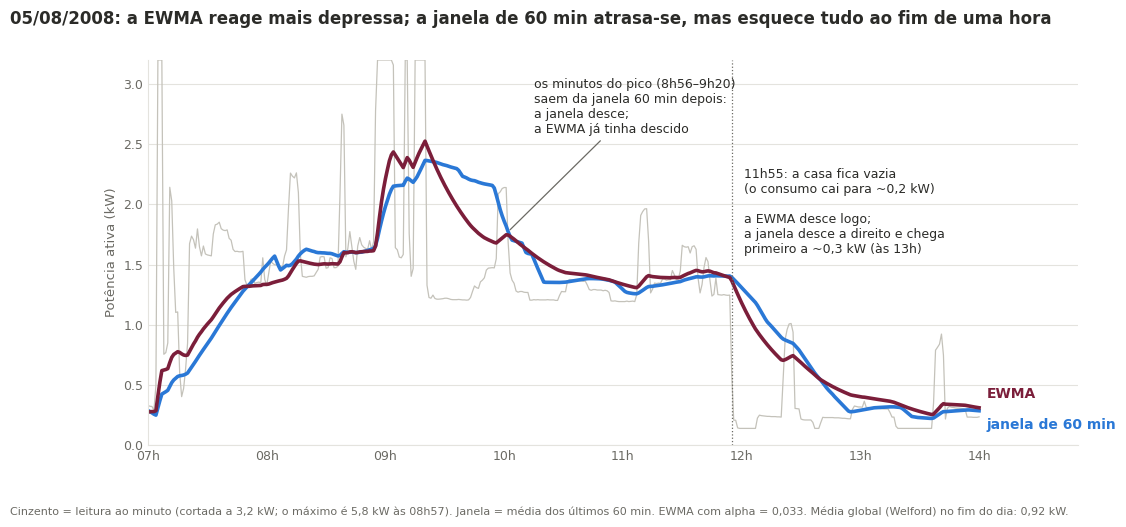

In [5]:
def plot_dia_fluxo(dia, caminho_png=None):
    """Manhã de um dia do fluxo: leituras ao minuto, janela de 60 min e EWMA, num só painel."""
    d = pd.Timestamp(dia)
    h = lambda hhmm: d + pd.Timedelta(f"{hhmm}:00")                  # "08:30" -> instante desse dia
    ini, fim = h("07:00"), h("14:00")
    x, o = serie.loc[ini:fim], online.loc[ini:fim]
    TETO = 3.2                                                        # eixo até 3,2 kW; os picos acima ficam cortados (assinalado)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(x.index, x.clip(upper=TETO).values, color=CINZA_DADOS, lw=0.9)
    ax.plot(o.index, o["janela_60min"], color=AZUL, lw=2.6)
    ax.plot(o.index, o["ewma"], color=BORDO, lw=2.6)

    # Nome de cada linha junto ao fim dela (em vez de legenda)
    ax.text(fim + pd.Timedelta(minutes=4), o["janela_60min"].iloc[-1] - 0.06, "janela de 60 min",
            color=AZUL, fontsize=10, fontweight="bold", va="top")
    ax.text(fim + pd.Timedelta(minutes=4), o["ewma"].iloc[-1] + 0.06, "EWMA",
            color=BORDO, fontsize=10, fontweight="bold", va="bottom")

    # 1) O pico sai da janela 60 min depois
    ax.annotate("os minutos do pico (8h56–9h20)\nsaem da janela 60 min depois:\na janela desce;\na EWMA já tinha descido",
                xy=(h("10:02"), o.loc[h("10:02"), "janela_60min"]), xytext=(h("10:15"), 3.05),
                fontsize=9, color=TINTA, va="top", arrowprops=dict(arrowstyle="-", color=TINTA_2, lw=0.9))

    # 2) A casa fica vazia
    vazia = x.loc[h("11:30"):h("12:30")].lt(1.0).idxmax()            # primeiro minuto abaixo de 1 kW
    ax.axvline(vazia, color=TINTA_2, lw=0.9, ls=":")
    ax.text(vazia + pd.Timedelta(minutes=6), 2.3,
            f"{vazia:%Hh%M}: a casa fica vazia\n(o consumo cai para ~0,2 kW)\n\na EWMA desce logo;\na janela desce a direito e chega\nprimeiro a ~0,3 kW (às 13h)",
            fontsize=9, color=TINTA, va="top")

    ax.set_xlim(ini, fim + pd.Timedelta(minutes=50))
    ax.set_ylim(0, TETO)
    ax.set_ylabel("Potência ativa (kW)", fontsize=9.5, color=TINTA_2)
    ax.xaxis.set_major_locator(mdates.HourLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Hh"))
    estilo(ax)
    fig.suptitle(f"{d:%d/%m/%Y}: a EWMA reage mais depressa; a janela de 60 min atrasa-se, mas esquece tudo ao fim de uma hora",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    num = lambda v, casas: f"{v:.{casas}f}".replace(".", ",")         # números com vírgula decimal
    fig.text(0.01, -0.03, f"Cinzento = leitura ao minuto (cortada a {num(TETO, 1)} kW; o máximo é {num(x.max(), 1)} kW às {x.idxmax():%Hh%M}). "
             f"Janela = média dos últimos 60 min. EWMA com alpha = {num(ALPHA, 3)}. "
             f"Média global (Welford) no fim do dia: {num(o['welford'].iloc[-1], 2)} kW.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_dia_fluxo("2008-08-05")
guardar_figura(fig, "parte_IV", "fluxo_dia")
plt.show()

Com base neste gráfico, podemos analisar que:
- **A EWMA reage mais depressa às mudanças.** Quando a casa fica vazia, às 11:55h, desce logo (às 12:15h está em 0,79 kW, contra 0,99 kW da janela), mas fica com uma "cauda" lenta, porque nunca esquece por completo o passado.
- **A janela de 60 min reage com atraso.** Os minutos do pico da manhã (8h56–9h20, até 5,8 kW) mantêm a média alta durante uma hora, e a janela só desce quando esses minutos saem dela, por volta das 10h. Em contrapartida, ao fim de 60 minutos esquece tudo, por isso chega primeiro ao nível da casa vazia (cerca de 0,3 kW às 13h, contra 0,4 kW da EWMA).
- **A média global (Welford) quase não se mexe** (0,92 kW no fim do dia), porque um único dia pesa pouco face a centenas de milhares de leituras. Serve para conhecer a casa a longo prazo e não para acompanhar o que está a acontecer no momento; por isso não aparece no gráfico.

### 4.2 Drift e anomalias

O **ADWIN** (*Adaptive Windowing*) guarda uma janela de valores recentes e, a cada valor novo, verifica se a média da parte mais antiga da janela é estatisticamente diferente da média da parte mais recente. Se for, assinala uma mudança (*drift*) e esquece a parte antiga. O parâmetro `delta` controla a exigência, ou seja, quanto menor, mais provas são precisas para assinalar uma mudança (usa-se o valor por omissão, 0,002). Usa-se também `clock = 1`, para o teste ser feito a cada valor novo.

In [6]:
# 4.2 - Agregados de 15 min e diários, calculados no próprio fluxo, e ADWIN sobre cada um
from river.drift import ADWIN
from src.fluxo import Agregador, AlarmeZ

DELTA = 0.002                                      # confiança do ADWIN (valor por omissão do river)
CLOCK = 1                                          # testa a cada valor novo (por omissão, o river só testa de 32 em 32)
ag15, agdia = Agregador("15min"), Agregador("1D")
adwin15, adwin_dia = ADWIN(delta=DELTA, clock=CLOCK), ADWIN(delta=DELTA, clock=CLOCK)
q15, dia_kwh, det15, det_dia = [], [], [], []


def novo_15min(fechado):
    """Recebe um período de 15 min acabado de fechar: guarda-o e passa-o ao ADWIN."""
    inicio_p, media, _ = fechado
    q15.append((inicio_p, media))
    adwin15.update(media)
    if adwin15.drift_detected:
        det15.append(inicio_p)


MIN_LEITURAS_DIA = int(0.8 * 24 * 60)              # um dia só conta com >= 80 % dos minutos com leitura (como na 1.2)


def novo_dia(fechado):
    """Recebe um dia acabado de fechar: energia do dia (kWh) para o ADWIN."""
    inicio_p, media, n = fechado
    if n < MIN_LEITURAS_DIA:                       # poucas leituras: a estimativa do dia não é fiável
        return
    kwh = media * 24                               # potência média (kW) x 24 h = energia do dia (kWh)
    dia_kwh.append((inicio_p, kwh))
    adwin_dia.update(kwh)
    if adwin_dia.drift_detected:
        det_dia.append(inicio_p)


for t, x in serie.items():                         # o mesmo fluxo, leitura a leitura
    if np.isnan(x):
        continue
    f = ag15.atualizar(t, x)
    if f:
        novo_15min(f)
    f = agdia.atualizar(t, x)
    if f:
        novo_dia(f)
novo_15min(ag15.fechar())                          # últimos períodos, ainda abertos no fim do fluxo
novo_dia(agdia.fechar())

q15 = pd.Series(dict(q15), name="kW")
dia = pd.Series(dict(dia_kwh), name="kWh")
det15, det_dia = pd.DatetimeIndex(det15), pd.DatetimeIndex(det_dia)
print(f"{len(q15)} períodos de 15 min | {len(dia)} dias")
print(f"ADWIN sobre os agregados de 15 min: {len(det15)} deteções")
print(f"ADWIN sobre a energia diária: {len(det_dia)} deteções -> {[f'{d:%d/%m/%Y}' for d in det_dia]}")


52425 períodos de 15 min | 545 dias
ADWIN sobre os agregados de 15 min: 216 deteções
ADWIN sobre a energia diária: 6 deteções -> ['27/07/2008', '11/09/2008', '09/12/2008', '28/05/2009', '26/07/2009', '16/09/2009']


Com base no output, podemos ver que:
- Só há **180 dias com ano anterior disponível**, de maio a outubro de 2009, pois a janela começa em maio de 2008;
- Em **maio, setembro e outubro de 2009, o consumo é praticamente igual ao do ano anterior** (diferenças entre −0,4 e +0,4 kWh/dia);
- Em **junho e julho de 2009 consome-se menos** do que em 2008 (cerca de −3,7 kWh/dia);
- Em **agosto de 2009 consome-se muito mais** do que em 2008 (+8,6 kWh/dia);
- **O ADWIN assinala as duas mudanças (16/08/2009 e 28/09/2009)**, no início e no fim deste bloco.

In [7]:
# Em que meses acontecem as deteções sobre os agregados de 15 min?
print(f"Em média, uma deteção a cada {len(q15) / len(det15) / 96:.1f} dias")
pd.DataFrame({"deteções": pd.Series(1, index=det15).resample("MS").sum()}).T.rename(
    columns=lambda m: f"{MESES_PT[m.month - 1]}/{m:%y}")


Em média, uma deteção a cada 2.5 dias


,mai/08,jun/08,jul/08,ago/08,set/08,out/08,nov/08,dez/08,jan/09,fev/09,mar/09,abr/09,mai/09,jun/09,jul/09,ago/09,set/09,out/09
deteções,15,11,8,4,9,15,18,17,16,19,14,13,8,8,8,7,12,14


Com base na tabela, podemos ver que:
- A **maioria das deteções acontece entre outubro de 2008 e abril de 2009**, a altura de outono/inverno, em que o consumo varia mais de hora para hora;
- O **mês com menos deteções é agosto de 2008**, o mês em que se detetou o período de baixo consumo, em que o consumo varia pouco;
- Nesta escala, o ADWIN reage à variabilidade normal do dia a dia assinalando, em média, uma **mudança a cada 2.5 dias**, o que é demasiado para representar mudanças de comportamento. Por isso, aplicou-se a seguir o **ADWIN à energia de cada dia**.

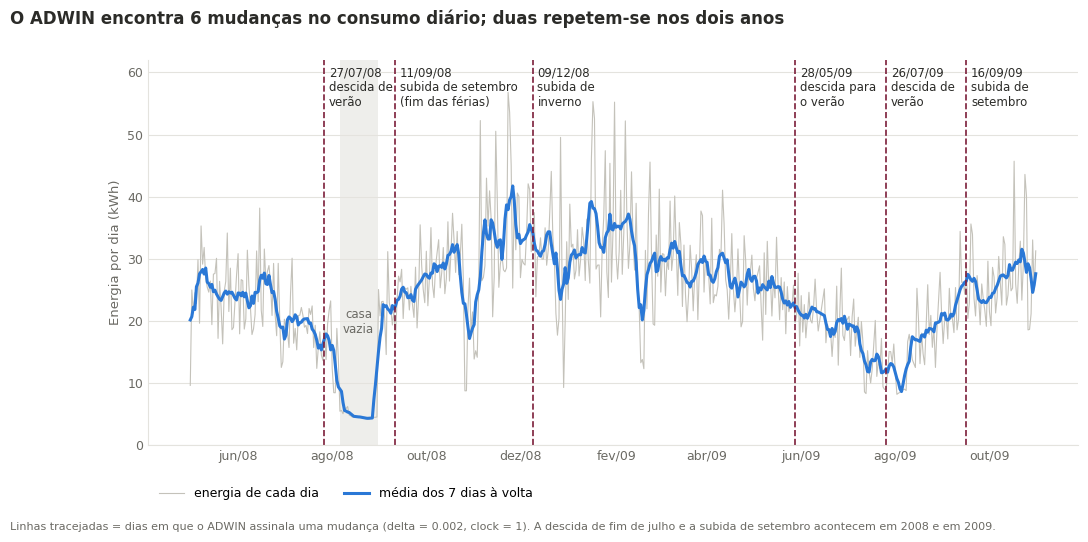

In [8]:
# O que cada mudança detetada significa (interpretação, ver o texto a seguir ao gráfico)
SIGNIFICADO = {"2008-07-27": "descida de\nverão", "2008-09-11": "subida de setembro\n(fim das férias)",
               "2008-12-09": "subida de\ninverno", "2009-05-28": "descida para\no verão",
               "2009-07-26": "descida de\nverão", "2009-09-16": "subida de\nsetembro"}


def plot_adwin(caminho_png=None):
    """Energia diária (e média de 7 dias) com as mudanças detetadas pelo ADWIN e o que significam."""
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(dia.index, dia.values, color=CINZA_DADOS, lw=0.8, label="energia de cada dia")

    ax.plot(dia.index, dia.rolling(7, center=True, min_periods=4).mean(), color=AZUL, lw=2.2,
            label="média dos 7 dias à volta")

    # Período de casa vazia (2.1), para contexto
    ax.axvspan(pd.Timestamp("2008-08-06"), pd.Timestamp("2008-08-31"), color=GRELHA, alpha=0.6, lw=0)
    ax.text(pd.Timestamp("2008-08-18"), 18, "casa\nvazia", ha="center", fontsize=8.5, color=TINTA_2)

    # Cada deteção: linha vertical + data + o que significa
    for d in det_dia:
        ax.axvline(d, color=BORDO, lw=1.2, ls="--")
        rotulo = f"{d:%d/%m/%y}\n{SIGNIFICADO.get(f'{d:%Y-%m-%d}', '')}"
        ax.text(d + pd.Timedelta(days=3), 61, rotulo, fontsize=8.5, color=TINTA, va="top", linespacing=1.2)

    ax.set_ylim(0, 62)
    ax.set_ylabel("Energia por dia (kWh)", fontsize=9.5, color=TINTA_2)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: (lambda d: f"{MESES_PT[d.month - 1]}/{d:%y}")(mdates.num2date(x))))
    ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2)
    estilo(ax)
    fig.suptitle(f"O ADWIN encontra {len(det_dia)} mudanças no consumo diário; duas repetem-se nos dois anos",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.06, f"Linhas tracejadas = dias em que o ADWIN assinala uma mudança (delta = {DELTA}, clock = {CLOCK}). "
             "A descida de fim de julho e a subida de setembro acontecem em 2008 e em 2009.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_adwin()
guardar_figura(fig, "parte_IV", "adwin")
plt.show()

Com base no gráfico, podemos observar que:
- **O ADWIN assinala apenas 6 mudanças no consumo diário ao longo dos 18 meses**, muito menos do que nos agregados de 15 minutos;
- Duas mudanças repetem-se quase na mesma altura nos dois anos, sendo elas a descida do consumo no final de julho (27/07/2008 e 26/07/2009) e a subida do consumo em setembro (11/09/2008 e 16/09/2009). Como acontecem nos dois anos, são um **drift recorrente (mudanças sazonais)**, provavelmente associado às férias de verão;
- A subida de 9 de dezembro (inverno) e a descida de 28 de maio (entrada no verão) indicam a **mudança de estação do ano**;
- As mudanças são assinaladas com algum atraso, porque o **ADWIN precisa de acumular vários dias diferentes do habitual** antes de ter a certeza de que houve uma mudança. Por exemplo, o regresso das férias acontece a 31/08/2008, mas só é assinalado a 11/09/2008, 11 dias depois.

Quando o ADWIN assinala uma mudança, interessa saber se essa é:
- **Sazonal**, ou seja, o consumo muda por causa da altura do ano (por exemplo, sobe no outono com o frio e a falta de luz), repetindo-se todos os anos, na mesma altura.
- **Estrutural**, ou seja, o consumo muda porque algo na casa mudou de vez (por exemplo, um aparelho novo ou mais uma pessoa a viver lá). Não se repete no ano seguinte e passa a ser o novo normal.

Para as distinguir, compara-se cada dia com a mesma semana do ano anterior. Se a mudança for sazonal, também aconteceu no ano anterior, e a diferença entre os dois anos fica perto de zero. Se for estrutural, não aconteceu no ano anterior, e a diferença mantém-se. Aplica-se depois o ADWIN a esta diferença.

Como os dados só cobrem 18 meses, **esta comparação só é possível de maio a outubro de 2009**, os **únicos meses com um ano anterior disponível**.

In [9]:
# Sazonal ou estrutural? Comparar cada dia com o MESMO período do ano anterior (que já passou no fluxo)
# Uma mudança sazonal repete-se todos os anos e desaparece nesta diferença; uma estrutural não.
adwin_aa = ADWIN(delta=DELTA, clock=CLOCK)
passado = {}                                       # energia dos dias que já chegaram
residuo, det_aa = [], []
for d, kwh in dia.items():                         # dias pela ordem em que chegam
    ref = [passado[r] for r in pd.date_range(d - pd.DateOffset(years=1) - pd.Timedelta(days=3), periods=7)
           if r in passado]                        # semana à volta do mesmo dia, um ano antes
    if len(ref) >= 4:
        r = kwh - np.mean(ref)
        residuo.append((d, r))
        adwin_aa.update(r)
        if adwin_aa.drift_detected:
            det_aa.append(d)
    passado[d] = kwh

residuo = pd.Series(dict(residuo), name="kWh face ao ano anterior")
print(f"Dias com ano anterior disponível: {len(residuo)} ({residuo.index.min():%d/%m/%Y} a {residuo.index.max():%d/%m/%Y})")
print(f"ADWIN sobre a diferença face ao ano anterior: {[f'{d:%d/%m/%Y}' for d in det_aa]}")
residuo.resample("MS").mean().round(1).rename(lambda m: f"{MESES_PT[m.month - 1]}/{m:%y}").to_frame("diferença média (kWh/dia)").T


Dias com ano anterior disponível: 180 (01/05/2009 a 31/10/2009)
ADWIN sobre a diferença face ao ano anterior: ['16/08/2009', '28/09/2009']


,mai/09,jun/09,jul/09,ago/09,set/09,out/09
diferença média (kWh/dia),-0.4,-3.6,-3.8,8.6,0.1,0.4


Com base no output, podemos ver que:
- Só há **180 dias com ano anterior disponível**, de maio a outubro de 2009, pois a janela começa em maio de 2008;
- Em **maio, setembro e outubro de 2009, o consumo é praticamente igual ao do ano anterior** (diferenças entre −0,4 e +0,4 kWh/dia);
- Em **junho e julho de 2009 consome-se menos** do que em 2008 (cerca de −3,7 kWh/dia);
- Em **agosto de 2009 consome-se muito mais** do que em 2008 (+8,6 kWh/dia),
- **O ADWIN assinala as duas mudanças (16/08/2009 e 28/09/2009)**, no início e no fim deste bloco.

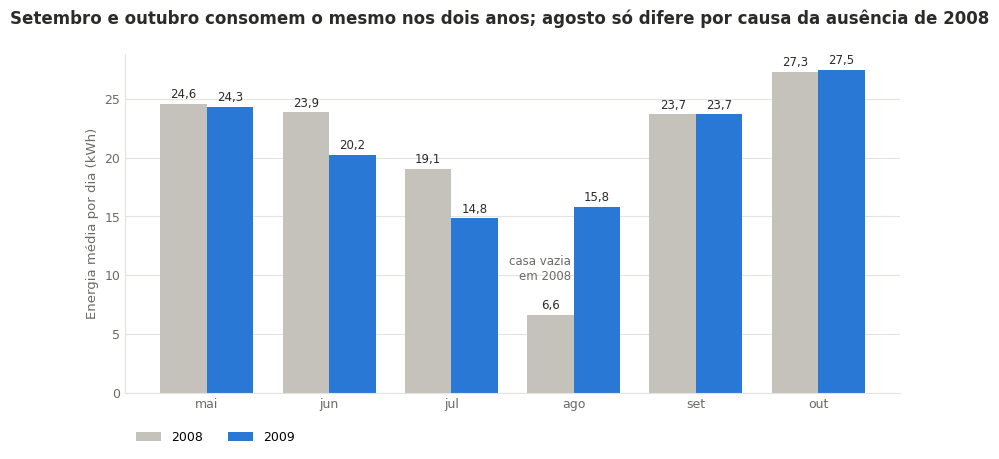

In [10]:
def plot_ano_contra_ano(caminho_png=None):
    """Consumo médio por mês, de maio a outubro: 2008 ao lado de 2009."""
    meses = [5, 6, 7, 8, 9, 10]
    media = dia.groupby([dia.index.year, dia.index.month]).mean()        # kWh/dia, por ano e mês
    v08 = [media[(2008, m)] for m in meses]
    v09 = [media[(2009, m)] for m in meses]

    fig, ax = plt.subplots(figsize=(10, 4.4))
    x = np.arange(len(meses)); w = 0.38
    b08 = ax.bar(x - w / 2, v08, w, color=CINZA_DADOS, label="2008")
    b09 = ax.bar(x + w / 2, v09, w, color=AZUL, label="2009")
    for barras, valores in ((b08, v08), (b09, v09)):
        ax.bar_label(barras, labels=[f"{v:.1f}".replace(".", ",") for v in valores], fontsize=8.5, color=TINTA, padding=2)
    ax.text(3 - 0.02, v08[3] + 3, "casa vazia\nem 2008", ha="right", fontsize=8.5, color=TINTA_2)
    ax.set_xticks(x, [MESES_PT[m - 1] for m in meses])
    ax.set_ylabel("Energia média por dia (kWh)", fontsize=9.5, color=TINTA_2)
    ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2)
    estilo(ax)
    fig.suptitle("Setembro e outubro consomem o mesmo nos dois anos; agosto só difere por causa da ausência de 2008",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_ano_contra_ano()
guardar_figura(fig, "parte_IV", "adwin_ano_contra_ano")
plt.show()

Com base no gráfico, podemos observar que:
- Em **maio, setembro e outubro, os dois anos consomem praticamente o mesmo** (por exemplo, 23,7 kWh/dia em setembro, nos dois anos). A subida de setembro que o ADWIN tinha assinalado na energia diária repete-se nos dois anos, o que confirma que é uma **mudança sazonal**;
- Em **agosto, 2009 parece consumir muito mais** (15,8 contra 6,6 kWh/dia), mas isso deve-se à **casa vazia em agosto de 2008**, e não a uma mudança em 2009. As duas deteções do ADWIN (16/08/2009 e 28/09/2009) correspondem a este afastamento;
- Em **junho e julho, 2009 consome menos** do que 2008 (cerca de 4 kWh/dia a menos), mas o ADWIN não o assinala. Com apenas um ano de comparação, não se pode dizer se é uma mudança permanente.

A comparação com o ano anterior só é possível em 6 meses. Por isso, usamos o dataset da Open-Meteo sobre a **temperatura média de cada dia** (`data/sceaux_temp_horaria_2008_2009.csv`), uma vez que, quanto mais frio está, mais se consome.

Para cada dia, estima-se quanto se esperaria consumir com aquela temperatura, através de uma **regressão linear aprendida só com os dias anteriores**, que é atualizada a cada dia que chega (classe `RegressaoOnline`). Aplica-se depois o ADWIN à diferença entre o consumo real e o esperado. Se uma mudança desaparecer nesta diferença, é explicada pela temperatura (sazonal) e, se se mantiver, foi outra coisa que mudou na casa.

In [11]:
# Temperatura média de cada dia (dados externos, Open-Meteo) e consumo esperado para essa temperatura
from src.fluxo import RegressaoOnline

tserie = (pd.read_csv("data/sceaux_temp_horaria_2008_2009.csv", parse_dates=["timestamp"])
          .set_index("timestamp")["temp_c"])
temp_dia = tserie.resample("D").mean()

reg = RegressaoOnline()
adwin_temp = ADWIN(delta=DELTA, clock=CLOCK)
linhas, det_temp = [], []
for d, kwh in dia.items():                          # dias pela ordem em que chegam
    T = temp_dia.get(d, np.nan)
    if np.isnan(T):
        continue
    if reg.n >= 30:                                 # só se prevê depois de 30 dias, para a reta já ser estável
        esperado = reg.prever(T)
        linhas.append({"dia": d, "temperatura (°C)": T, "kWh": kwh, "esperado (kWh)": esperado,
                       "diferença (kWh)": kwh - esperado})
        adwin_temp.update(kwh - esperado)
        if adwin_temp.drift_detected:
            det_temp.append(d)
    reg.atualizar(T, kwh)                           # o dia só entra na reta depois de ter sido previsto

temp_res = pd.DataFrame(linhas).set_index("dia")
rho = dia.corr(temp_dia.reindex(dia.index), method="spearman")
print(f"Correlação (Spearman) entre a energia e a temperatura de cada dia: {rho:.2f}")
print(f"Reta no fim do fluxo: consumo = {reg.a:.1f} {reg.b:+.2f} x temperatura (kWh/dia)")
print(f"ADWIN sobre a diferença face ao esperado: {[f'{d:%d/%m/%Y}' for d in det_temp]}")
temp_res["diferença (kWh)"].resample("MS").mean().round(1).rename(
    lambda m: f"{MESES_PT[m.month - 1]}/{m:%y}").to_frame("diferença média (kWh/dia)").T


Correlação (Spearman) entre a energia e a temperatura de cada dia: -0.61
Reta no fim do fluxo: consumo = 34.4 -0.81 x temperatura (kWh/dia)
ADWIN sobre a diferença face ao esperado: ['15/08/2008', '18/09/2008', '03/11/2008', '08/08/2009']


dia,mai/08,jun/08,jul/08,ago/08,set/08,out/08,nov/08,dez/08,jan/09,fev/09,mar/09,abr/09,mai/09,jun/09,jul/09,ago/09,set/09,out/09
diferença média (kWh/dia),2.6,-1.1,-3.7,-13.0,2.1,0.9,3.6,-4.1,0.5,-1.7,0.6,2.5,1.3,-1.1,-4.0,-1.3,3.0,2.8


Com base nos dados, podemos verificar que:
- **Quanto mais frio está, mais se consome**, como se pode ver através da correlação de −0,61 entre a energia e a temperatura de cada dia;
- No fim do fluxo, a reta indica que cada grau a menos acrescenta cerca de **0,8 kWh/dia** ao consumo;
- Descontado o efeito da temperatura, o **ADWIN assinala apenas 4 mudanças**, contra as 6 da energia diária: **15/08/2008 e 18/09/2008** (início e fim da ausência de agosto de 2008), **03/11/2008** (depois de vários dias abaixo do esperado, a 26–27/10 e 1–3/11, o consumo passa a ficar acima do que a temperatura explica) e **08/08/2009** (a semana de ausência de 2009). Assim, depois de descontar a temperatura, o que sobra são sobretudo **ausências**, ou seja, mudanças de comportamento e não de estação;
- A maior diferença face ao esperado é em **agosto de 2008 (−13 kWh/dia), o período de casa vazia, que nenhuma temperatura explica**.

In [12]:
# As 6 mudanças da energia diária acompanham mudanças de temperatura? (interpretação, depois do fluxo)
linhas = []
for d in det_dia:
    antes = slice(d - pd.Timedelta(days=14), d - pd.Timedelta(days=1))   # duas semanas antes
    depois = slice(d, d + pd.Timedelta(days=13))                         # duas semanas depois
    linhas.append({"deteção": f"{d:%d/%m/%Y}",
                   "temperatura antes (°C)": temp_dia[antes].mean(), "temperatura depois (°C)": temp_dia[depois].mean(),
                   "kWh/dia antes": dia[antes].mean(), "kWh/dia depois": dia[depois].mean()})
pd.DataFrame(linhas).set_index("deteção").round(1)


,temperatura antes (°C),temperatura depois (°C),kWh/dia antes,kWh/dia depois
deteção,,,,
27/07/2008,18.2,21.0,18.0,12.9
11/09/2008,17.4,13.2,18.4,24.1
09/12/2008,3.2,3.1,34.7,32.8
28/05/2009,14.8,14.9,24.3,21.4
26/07/2009,19.2,19.5,12.5,10.9
16/09/2009,16.4,16.2,22.7,24.8


Com base na tabela, podemos ver que:
- **Só a subida de 11/09/2008 acompanha uma descida clara da temperatura** (de 17,4 °C para 13,2 °C), mas coincide também com o regresso das férias;
- As **descidas de fim de julho (2008 e 2009) acontecem sem a temperatura descer** (em 2008 até fica mais calor), o que reforça que se devem às férias e não ao tempo;
- Nas restantes (09/12/2008, 28/05/2009 e 16/09/2009), a temperatura praticamente não muda (menos de 0,3 °C) nas duas semanas à volta da deteção, provavelmente porque o ADWIN assinala a mudança com atraso, quando a temperatura já tinha mudado.

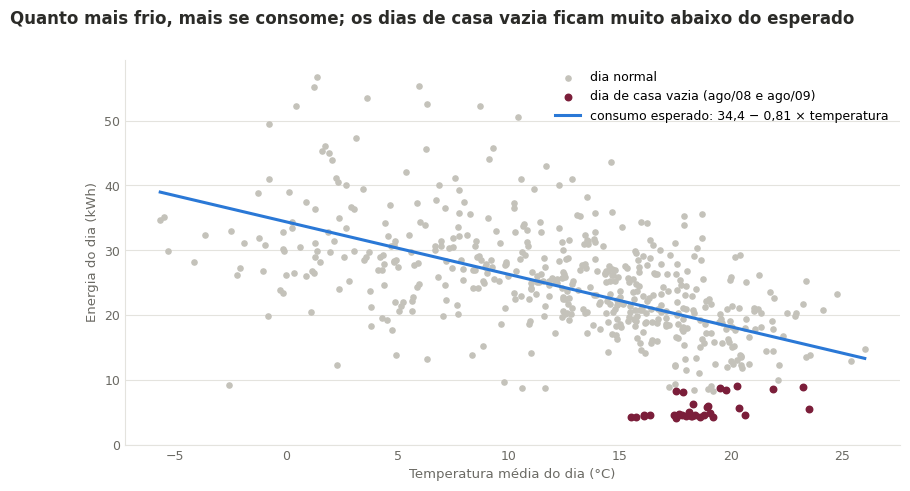

In [13]:
def plot_temperatura(caminho_png=None):
    """Cada dia como um ponto: energia contra temperatura, com a reta aprendida no fluxo."""
    tab = pd.DataFrame({"kWh": dia, "T": temp_dia.reindex(dia.index)}).dropna()
    vazia = ((tab.index >= "2008-08-06") & (tab.index <= "2008-08-30")) | \
            ((tab.index >= "2009-08-02") & (tab.index <= "2009-08-08"))       # casa vazia (2.1)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(tab.loc[~vazia, "T"], tab.loc[~vazia, "kWh"], s=14, color=CINZA_DADOS, label="dia normal")
    ax.scatter(tab.loc[vazia, "T"], tab.loc[vazia, "kWh"], s=22, color=BORDO, label="dia de casa vazia (ago/08 e ago/09)")
    xs = np.linspace(tab["T"].min(), tab["T"].max(), 50)
    ax.plot(xs, reg.prever(xs), color=AZUL, lw=2.2,
            label=f"consumo esperado: {reg.a:.1f} − {-reg.b:.2f} × temperatura".replace(".", ","))
    ax.set_xlabel("Temperatura média do dia (°C)", fontsize=9.5, color=TINTA_2)
    ax.set_ylabel("Energia do dia (kWh)", fontsize=9.5, color=TINTA_2)
    ax.set_ylim(0, None)
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    estilo(ax)
    fig.suptitle("Quanto mais frio, mais se consome; os dias de casa vazia ficam muito abaixo do esperado",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_temperatura()
guardar_figura(fig, "parte_IV", "adwin_temperatura")
plt.show()

Tendo em conta que cada ponto é um dia, podemos observar que:
- **Quanto mais frio está, mais se consome**, pois a reta desce cerca de 0,8 kWh/dia por cada grau a mais;
- A maioria dos dias fica à volta da reta, ou seja, **as mudanças de estação são explicadas pela temperatura**. É por isso que, descontada a temperatura, o ADWIN deixa de assinalar a subida de inverno e a descida para o verão;
- Os **dias de casa vazia** (agosto de 2008 e a semana de 2 a 8 de agosto de 2009) ficam **muito abaixo da reta**, ou seja, nestes dias a temperatura não explica o consumo, porque não estava ninguém em casa.

### Alarme de anomalias com z-score em janela

Para cada leitura calcula-se `z = (leitura − média da janela) / desvio-padrão da janela`, usando a janela **anterior**, sem a própria leitura. \
Há alarme quando |z| ultrapassa o limiar. \
Começa-se ao minuto, com janelas de 30 a 120 min e limiares de 3 a 5.

In [14]:
# Alarme de anomalias com z-score em janela, ao MINUTO: quantos alarmes para cada janela e limiar?
N_DIAS = serie.dropna().index.normalize().nunique()
em_ausencia = lambda idx: (idx >= "2008-08-06") & (idx < "2008-08-31")   # casa vazia (2.1)


def contar_alarmes(fluxo, **config):
    """Passa o fluxo pelo AlarmeZ e devolve os alarmes (instante -> z)."""
    alarme = AlarmeZ(**config)
    out = {}
    for t, x in fluxo.items():
        if np.isnan(x):
            continue
        z, a = alarme.atualizar(t, x)
        if a:
            out[t] = z
    return pd.Series(out, dtype=float)


linhas = []
for minutos in (30, 60, 120):
    for limiar in (3, 4, 5):
        a = contar_alarmes(serie, minutos=minutos, limiar=limiar, min_leituras=minutos // 2)
        linhas.append({"janela (min)": minutos, "limiar |z|": limiar, "alarmes": len(a),
                       "alarmes por dia": len(a) / N_DIAS,
                       "por dia, na casa vazia": em_ausencia(a.index).sum() / 25})
tab_minuto = pd.DataFrame(linhas).set_index(["janela (min)", "limiar |z|"])
tab_minuto.round(1)


alarmes  alarmes por dia  por dia, na casa vazia
janela (min) limiar |z|                                                  
30           3             46756             85.3                    85.9
             4             25301             46.2                    45.1
             5             15761             28.8                    27.4
60           3             37520             68.5                    70.8
             4             22597             41.2                    58.5
             5             13536             24.7                    37.8
120          3             34278             62.6                    62.4
             4             16305             29.8                    31.8
             5              8134             14.8                     7.2

Com base na tabela, vemos que:
- **Ao minuto, o alarme dispara demasiadas vezes** pois, mesmo na configuração mais exigente (janela de 120 min e limiar 5), há cerca de **15 alarmes por dia** e, na menos exigente (30 min e limiar 3), chega a **85 alarmes por dia**;
- Aumentar a janela ou o limiar reduz os alarmes, mas nunca para um número que um operador consiga acompanhar. Isto acontece porque cada aparelho que liga como, por exemplo, o forno, é uma subida brusca face à última hora;
- **Na casa vazia, as janelas de 30 e 60 min dão tantos ou mais alarmes do que nos dias normais** (por exemplo, 58.5 por dia contra 41.2 com 60 min e limiar 4), pois a janela é quase constante, o desvio-padrão fica minúsculo e o simples ciclo do frigorífico dá valores de z enormes. Só com 120 min e limiar 5 os alarmes na casa vazia descem (7.2 por dia).

Por isso, testou-se a seguir o mesmo alarme sobre as **médias de 15 minutos**, com janelas mais longas e um desvio mínimo de 0,1 kW Abaixo disto, a janela é tratada como quase constante.

In [15]:
# Alternativa: o mesmo alarme sobre as médias de 15 min, com janelas mais longas e um desvio mínimo
DESVIO_MIN = 0.1                                   # kW: abaixo disto, a janela é tratada como "quase constante"
linhas = []
for horas in (6, 24, 24 * 7):
    for limiar in (3, 4, 5):
        a = contar_alarmes(q15, minutos=horas * 60, limiar=limiar, min_leituras=horas * 2, desvio_min=DESVIO_MIN)
        linhas.append({"janela (h)": horas, "limiar |z|": limiar, "alarmes": len(a),
                       "alarmes por dia": len(a) / N_DIAS, "na casa vazia (25 dias)": em_ausencia(a.index).sum(),
                       "alarmes de queda (z < 0)": (a < 0).sum()})
tab_15 = pd.DataFrame(linhas).set_index(["janela (h)", "limiar |z|"])
tab_15.round(2)


alarmes  alarmes por dia  na casa vazia (25 dias)  \
janela (h) limiar |z|                                                      
6          3              3165             5.78                        3   
           4              1805             3.29                        2   
           5              1134             2.07                        2   
24         3              1045             1.91                        5   
           4               360             0.66                        3   
           5               124             0.23                        2   
168        3               858             1.57                        2   
           4               290             0.53                        0   
           5               106             0.19                        0   

                       alarmes de queda (z < 0)  
janela (h) limiar |z|                            
6          3                                218  
           4                                 87  
           5                                 41  
24         3                                  0  
           4                                  0  
           5                                  0  
168        3                                  0  
           4                                  0  
           5                                  0

Com base na tabela, vemos que:
- Com as **médias de 15 minutos**, o número de alarmes **cai de 0.19 para 5.78 por dia**, muito menos do que ao minuto;
- A **janela de 6 horas ainda dá alarmes a mais** (2 a 6 por dia), mas é a única que assinala quedas de consumo (41 a 218 alarmes com z < 0);
- Com a **janela de 24 horas e limiar 4**, há **0.66 alarmes por dia**, e ainda se apanham 3 situações durante a casa vazia;
- A **janela de 7 dias (168 h) dá menos alarmes**, mas, com limiar 4 ou 5, não assinala nenhum durante a casa vazia, pois a janela longa "lembra-se" das semanas normais e um consumo pequeno numa casa vazia já não sobressai;
- Com janelas de 24 horas ou mais **não há alarmes de queda**, pois o z-score serve para detetar picos.

A seguir, avaliam-se **5 alarmes da configuração com janela de 24 horas e limiar 4**.

In [16]:
# Configuração escolhida para avaliar: médias de 15 min, janela das últimas 24 h, limiar 4
CONFIG = dict(minutos=24 * 60, limiar=4, min_leituras=48, desvio_min=DESVIO_MIN)
alarme = AlarmeZ(**CONFIG)
linhas = []
for t, x in q15.items():
    media_antes, desvio_antes = alarme.janela.media, alarme.janela.desvio   # janela ANTES desta leitura
    z, a = alarme.atualizar(t, x)
    if a:
        linhas.append({"instante": t, "kW (15 min)": x, "média 24 h": media_antes,
                       "desvio 24 h": desvio_antes, "z": z})
alarmes = pd.DataFrame(linhas).set_index("instante")
print(f"{len(alarmes)} alarmes ({len(alarmes) / N_DIAS:.2f} por dia). Os 8 com maior |z|:")
alarmes.reindex(alarmes["z"].abs().sort_values(ascending=False).index).head(8).round(2)


360 alarmes (0.66 por dia). Os 8 com maior |z|:


,kW (15 min),média 24 h,desvio 24 h,z
instante,,,,
2008-08-31 14:15:00,2.20,0.20,0.10,19.98
2008-05-02 09:45:00,3.88,0.42,0.29,12.06
2008-08-09 15:30:00,1.96,0.22,0.16,10.98
2008-10-28 18:45:00,3.52,0.39,0.31,10.11
2008-08-04 18:00:00,3.58,0.39,0.32,9.91
2008-08-09 15:00:00,1.20,0.20,0.10,9.85
2009-02-22 17:00:00,7.72,0.60,0.75,9.50
2008-07-16 21:00:00,5.45,0.65,0.51,9.42


Com base na tabela, podemos ver que:
- Com a janela de 24 horas e o limiar 4 há **360 alarmes, cerca de 0.66 por dia** ;
- Os alarmes com maior z **não são os de consumo mais alto**, mas sim os que acontecem **depois de 24 h muito calmas**. Em quase todos, a média das 24 h anteriores está entre 0.2 e 0.65 kW, bem abaixo da média da casa (cerca de 1 kW), por isso um consumo normal parece enorme;
- O **consumo mais alto da lista (7,7 kW, a 22/02/2009) só aparece em 7.º lugar**, porque as 24 horas anteriores já tinham mais variação (desvio de 0.75 kW);
- Alguns alarmes **pertencem ao mesmo acontecimento**, como os de 09/08/2008 às 15h00 e às 15h30, o que significa que há menos situações diferentes do que alarmes;
- O alarme de 02/05/2008 acontece no **segundo dia do fluxo**, quando a janela ainda só tem cerca de um dia de dados, pelo que a comparação é pouco fiável.

A seguir, escolhem-se 5 alarmes que cobrem situações diferentes, para avaliar quais são reais e quais são falsos.

In [17]:
# Os 5 alarmes a avaliar: 4 alarmes fortes, escolhidos entre os de maior z para cobrir situações
# diferentes (regresso de férias, casa vazia, dia útil, fim de semana), e 1 alarme típico perto do
# limiar, num fim de tarde de inverno (a altura do dia com mais alarmes)
AVALIAR = ["2008-08-31 14:15", "2008-08-09 15:30", "2008-10-28 18:45", "2009-02-22 17:00", "2008-11-04 19:00"]
wh = tratado.loc[:, ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]].copy()
wh["Outros"] = tratado["Global_active_power"] * 1000 / 60 - wh.sum(axis=1)
wh.columns = ["Cozinha", "Lavandaria", "Aquecedor/AC", "Outros"]

linhas = []
for i, a in enumerate(AVALIAR, start=1):
    t = pd.Timestamp(a)
    r = alarmes.loc[t]
    circ = wh.loc[t:t + pd.Timedelta(minutes=14)].sum()            # Wh de cada circuito nesses 15 min
    linhas.append({"#": i, "instante": f"{DIAS[t.dayofweek]} {t:%d/%m/%Y %H:%M}", "kW (15 min)": r["kW (15 min)"],
                   "média 24 h": r["média 24 h"], "z": r["z"], **circ.round(0).to_dict()})
pd.DataFrame(linhas).set_index("#").round(2)


,instante,kW (15 min),média 24 h,z,Cozinha,Lavandaria,Aquecedor/AC,Outros
#,,,,,,,,
1,dom 31/08/2008 14:15,2.20,0.20,19.98,0.0,0.0,268.0,282.0
2,sáb 09/08/2008 15:30,1.96,0.22,10.98,0.0,0.0,10.0,481.0
3,ter 28/10/2008 18:45,3.52,0.39,10.11,569.0,0.0,0.0,311.0
4,dom 22/02/2009 17:00,7.72,0.60,9.50,240.0,1003.0,249.0,437.0
5,ter 04/11/2008 19:00,4.32,0.67,4.39,0.0,650.0,0.0,430.0


Com base na tabela, podemos ver que:
- Cada linha é um alarme, onde se compara o consumo médio desses **15 minutos** (`kW (15 min)`) com a **média das 24 horas anteriores**. As últimas quatro colunas mostram quanta energia (Wh) gastou cada circuito nesses 15 minutos, sendo «Outros» a parte que nenhuma submedição mede;
- Nos alarmes **#1 e #2**, a média das 24 horas anteriores é de apenas **0.20 kW**, pois a casa estava vazia. Assim, um consumo de cerca de 2 kW já dá um z muito alto (20 e 11). No #2 quase tudo é «Outros» (481 Wh), sem cozinha nem lavandaria;
- Nos alarmes **#3 e #5**, a média das 24 horas anteriores também é baixa (0,39 e 0,67 kW), uma vez que esses dias anteriores foram de pouco consumo, mas o que se vê é a rotina normal ao fim do dia, como a cozinha (569 Wh) no #3 e a lavandaria (650 Wh) no #5;
- O alarme **#4** tem o consumo mais alto (**7.72 kW**), com todos os circuitos ligados ao mesmo tempo, em especial a lavandaria (1003 Wh);
Assim, **um z alto nem sempre significa um consumo alto** - depende também do quão baixa estava a média das 24 horas anteriores.

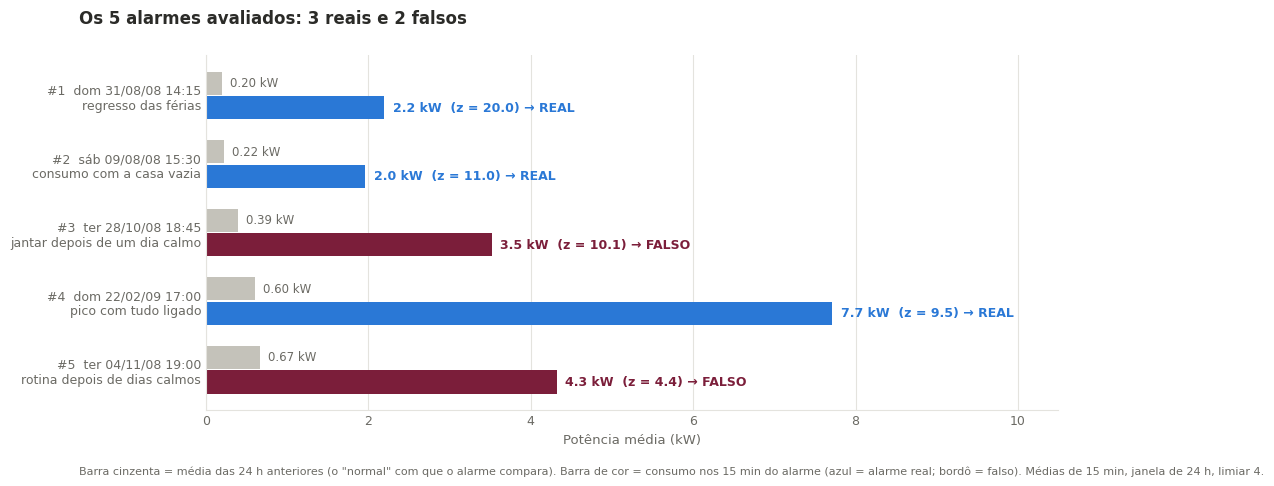

In [18]:
# O que aconteceu em cada alarme e a avaliação (ver a tabela a seguir ao gráfico)
LEGENDA_ALARME = {1: ("regresso das férias", "real"), 2: ("consumo com a casa vazia", "real"),
                  3: ("jantar depois de um dia calmo", "falso"), 4: ("pico com tudo ligado", "real"),
                  5: ("rotina depois de dias calmos", "falso")}


def plot_alarmes(caminho_png=None):
    """Para cada alarme: consumo nos 15 min do alarme vs. média das 24 h anteriores, e se foi real ou falso."""
    fig, ax = plt.subplots(figsize=(11, 4.6))
    y = np.arange(len(AVALIAR))[::-1]                       # alarme #1 em cima
    rotulos = []
    for yi, (i, a) in zip(y, enumerate(AVALIAR, start=1)):
        t = pd.Timestamp(a)
        r = alarmes.loc[t]
        o_que, avaliacao = LEGENDA_ALARME[i]
        cor = AZUL if avaliacao == "real" else BORDO
        ax.barh(yi + 0.18, r["média 24 h"], height=0.34, color=CINZA_DADOS)
        ax.barh(yi - 0.18, r["kW (15 min)"], height=0.34, color=cor)
        ax.text(r["kW (15 min)"] + 0.1, yi - 0.18, f"{r['kW (15 min)']:.1f} kW  (z = {r['z']:.1f}) → {avaliacao.upper()}",
                va="center", fontsize=9, color=cor, fontweight="bold")
        ax.text(r["média 24 h"] + 0.1, yi + 0.18, f"{r['média 24 h']:.2f} kW", va="center", fontsize=8.5, color=TINTA_2)
        rotulos.append(f"#{i}  {DIAS[t.dayofweek]} {t:%d/%m/%y %H:%M}\n{o_que}")
    ax.set_yticks(y, rotulos, fontsize=9)
    ax.set_xlim(0, 10.5)
    ax.set_xlabel("Potência média (kW)", fontsize=9.5, color=TINTA_2)
    estilo(ax)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=GRELHA, lw=0.8)
    fig.suptitle("Os 5 alarmes avaliados: 3 reais e 2 falsos", x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.03, "Barra cinzenta = média das 24 h anteriores (o \"normal\" com que o alarme compara). "
             "Barra de cor = consumo nos 15 min do alarme (azul = alarme real; bordô = falso). "
             "Médias de 15 min, janela de 24 h, limiar 4.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_alarmes()
guardar_figura(fig, "parte_IV", "alarmes_avaliados")
plt.show()

Com base no gráfico, podemos avaliar cada alarme da seguinte forma:
- **#1 (dom 31/08/2008, 14:15) — real.** depois de 25 dias a cerca de 0,2 kW, a casa volta a consumir 2,2 kW, sobretudo com o aquecedor de água a reaquecer e «Outros». É um acontecimento verdadeiro, mas benigno, pois não exige nenhuma ação;
- **#2 (sáb 09/08/2008, 15:30) — real.** A meio da ausência, a casa consome 1 a 2 kW durante cerca de uma hora, quase tudo em «Outros», sem cozinha nem lavandaria. É o alarme mais útil, uma vez que se trata de consumo numa casa que devia estar vazia;
- **#3 (ter 28/10/2008, 18:45) — falso.** É um jantar normal (cozinha 569 Wh, 3,5 kW). O z é alto apenas porque as 24 horas anteriores incluem o dia 27/10, um dia de consumo muito baixo (8,7 kWh);
- **#4 (dom 22/02/2009, 17:00) — real.** A casa consome 7,7 kW em média durante 15 minutos, com todos os circuitos ligados ao mesmo tempo (lavandaria 1003 Wh, cozinha, aquecedor e «Outros»). É a 3.ª média de 15 minutos mais alta de toda a janela, o que é relevante para a potência contratada;
- **#5 (ter 04/11/2008, 19:00) — falso.** É a rotina normal de um fim de tarde de inverno, com a máquina de roupa (650 Wh), e há valores parecidos antes e depois. Só passa o limiar porque os dois dias anteriores foram calmos (14–15 kWh).

Assim, **3 alarmes são reais (um deles benigno) e 2 são falsos**, sendo que os dois falsos têm a mesma causa.

### Recomendação à sala de controlo

- **Usar médias de 15 minutos, não leituras ao minuto.** Ao minuto há dezenas de alarmes por dia, quase todos causados por aparelhos a ligar.
- **Comparar com as últimas 24 horas e usar o limiar 5 para os alarmes imediatos.** Isto dá cerca de 7 alarmes por mês. Os alarmes entre 4 e 5 (cerca de 12 por mês) podem ficar numa lista para rever uma vez por dia, sem interromper o operador.
- **Preferir a janela de 24 horas à de 7 dias.** A de 7 dias dá menos alarmes, mas não deteta consumo quando a casa está vazia (o alarme #2), que foi o caso mais útil.
- **Ter em conta um ponto fraco:** depois de um dia de pouco consumo, o regresso à rotina normal pode gerar falsos alarmes (#3 e #5). Para o evitar, cada leitura poderia ser comparada com o consumo habitual daquela hora e dia da semana.
- **Deixar as descidas e as mudanças de nível para o ADWIN.** O z-score serve para picos. As ausências e as mudanças de estação são detetadas pelo ADWIN sobre a energia diária, com alguns dias de atraso. Antes de agir, convém ver se a mudança também aconteceu no ano anterior ou se é explicada pela temperatura. Se for, é sazonal.